In [7]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
BASE_DIR = Path("../data/raw")

# 1. Load tabel utama postings
postings = pd.read_csv(BASE_DIR / "postings.csv", low_memory=False)
print(f"Total data mentah postings.csv: {postings.shape[0]:,} baris, {postings.shape[1]} kolom")

# 2. Filter hanya baris yang punya normalized_salary valid (mata uang USD & rentang wajar $15k - $500k/tahun)
df = postings[postings["normalized_salary"].notna()].copy()
df = df[df["currency"] == "USD"]
df = df[(df["normalized_salary"] >= 15000) & (df["normalized_salary"] <= 500000)]

print(f"Jumlah data valid setelah filter gaji: {len(df):,} baris (Syarat minimal proyek: 5.000)")
print("\nStatistik Deskriptif Gaji Tahunan (USD):")
print(df["normalized_salary"].describe().round(2))

Total data mentah postings.csv: 123,849 baris, 31 kolom
Jumlah data valid setelah filter gaji: 35,509 baris (Syarat minimal proyek: 5.000)

Statistik Deskriptif Gaji Tahunan (USD):
count     35509.00
mean      95792.85
std       56501.41
min       15000.00
25%       52124.80
50%       82500.00
75%      125000.00
max      500000.00
Name: normalized_salary, dtype: float64


merging:

In [8]:
# Load tabel pendukung
companies = pd.read_csv(BASE_DIR / "companies/companies.csv", usecols=["company_id", "company_size"])
job_skills = pd.read_csv(BASE_DIR / "jobs/job_skills.csv").merge(
    pd.read_csv(BASE_DIR / "mappings/skills.csv"), on="skill_abr", how="left"
)
job_industries = pd.read_csv(BASE_DIR / "jobs/job_industries.csv").merge(
    pd.read_csv(BASE_DIR / "mappings/industries.csv"), on="industry_id", how="left"
)

# Agregasi multi-skill dan multi-industry per job_id menjadi teks dipisah koma
skills_agg = job_skills.groupby("job_id")["skill_name"].apply(lambda x: ", ".join(x.dropna().unique())).reset_index()
ind_agg = job_industries.groupby("job_id")["industry_name"].apply(lambda x: ", ".join(x.dropna().unique())).reset_index()

# Merge ke dataframe utama
df = df.merge(companies, on="company_id", how="left")
df = df.merge(skills_agg, on="job_id", how="left")
df = df.merge(ind_agg, on="job_id", how="left")

print(f"Ukuran dataset setelah merging: {df.shape[0]:,} baris, {df.shape[1]} kolom")
df[["job_id", "title", "skill_name", "industry_name", "company_size", "normalized_salary"]].head(3)

Ukuran dataset setelah merging: 35,509 baris, 34 kolom


,job_id,title,skill_name,industry_name,company_size,normalized_salary
0,921716,Marketing Coordinator,"Marketing, Sales",Real Estate,2.0,38480.0
1,1829192,Mental Health Therapist/Counselor,Health Care Provider,NaN,NaN,83200.0
2,10998357,Assitant Restaurant Manager,"Management, Manufacturing",Restaurants,1.0,55000.0


Persentase Missing Values:
                             Missing  Missing (%)
skills_desc                   35179        99.07
remote_allowed                30741        86.57
applies                       26850        75.61
formatted_experience_level     7979        22.47
company_size                   2203         6.20
skill_name                      527         1.48
views                           478         1.35
industry_name                   357         1.01
title                             0         0.00
description                       1         0.00
formatted_work_type               0         0.00


C:\Users\LEGION\AppData\Local\Temp\ipykernel_32188\2880878323.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="formatted_experience_level", y="normalized_salary", order=exp_order, ax=axes[1], palette="Blues")
C:\Users\LEGION\AppData\Local\Temp\ipykernel_32188\2880878323.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df.dropna(subset=["company_size"]), x="company_size", y="normalized_salary", ax=axes[2], palette="Oranges")


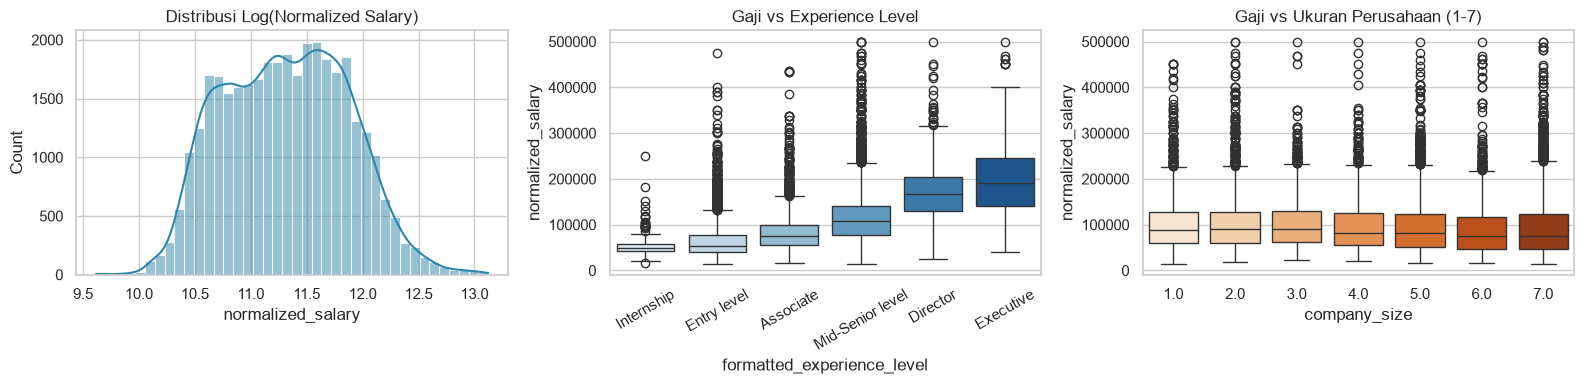

In [9]:
# 1. Cek missing values pada fitur yang akan dipakai
fitur_cek = ["title", "description", "skills_desc", "skill_name", "industry_name",
             "formatted_experience_level", "formatted_work_type", "remote_allowed", "company_size", "views", "applies"]
missing_df = pd.DataFrame({
    "Missing": df[fitur_cek].isna().sum(),
    "Missing (%)": (df[fitur_cek].isna().mean() * 100).round(2)
}).sort_values("Missing (%)", ascending=False)
print("Persentase Missing Values:\n", missing_df)

# 2. Visualisasi Target Gaji & Hubungannya dengan Fitur Tabular
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(np.log1p(df["normalized_salary"]), bins=40, kde=True, ax=axes[0], color="#2E86AB")
axes[0].set_title("Distribusi Log(Normalized Salary)")

exp_order = df.groupby("formatted_experience_level")["normalized_salary"].median().sort_values().index
sns.boxplot(data=df, x="formatted_experience_level", y="normalized_salary", order=exp_order, ax=axes[1], palette="Blues")
axes[1].set_title("Gaji vs Experience Level")
axes[1].tick_params(axis="x", rotation=30)

sns.boxplot(data=df.dropna(subset=["company_size"]), x="company_size", y="normalized_salary", ax=axes[2], palette="Oranges")
axes[2].set_title("Gaji vs Ukuran Perusahaan (1-7)")

plt.tight_layout()
plt.show()

In [10]:
import re

def clean_text(text):
    text = re.sub(r"<.*?>", " ", str(text))
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-zA-Z0-9\s\+\#]", " ", text.lower())
    return re.sub(r"\s+", " ", text).strip()

# Gabungkan seluruh fitur teks (Judul + Deskripsi + Syarat + Skill + Industri)
text_cols = ["title", "description", "skills_desc", "skill_name", "industry_name"]
df["combined_text"] = df[text_cols].fillna("").agg(" ".join, axis=1).apply(clean_text)

# Imputasi nilai kosong pada fitur tabular
df["formatted_experience_level"] = df["formatted_experience_level"].fillna("Unknown")
df["formatted_work_type"] = df["formatted_work_type"].fillna("Unknown")
df["remote_allowed"] = df["remote_allowed"].fillna(0).astype(int)
df["company_size"] = df["company_size"].fillna(0).astype(int)
df["views"] = df["views"].fillna(0)
df["applies"] = df["applies"].fillna(0)

# Simpan kolom final untuk tahap modeling
final_cols = [
    "job_id", "title", "combined_text",
    "formatted_experience_level", "formatted_work_type", "remote_allowed",
    "company_size", "views", "applies", "normalized_salary"
]
output_path = Path("../data/processed/salary_multimodal_clean.csv")
df[final_cols].to_csv(output_path, index=False)
print(f"Selesai! Dataset bersih tersimpan di: {output_path} ({len(df):,} baris)")

Selesai! Dataset bersih tersimpan di: ..\data\processed\salary_multimodal_clean.csv (35,509 baris)
